# 2D Shin–Metiu TGIFS without harmonic-potential separation

This notebook implements

$$
H = \frac{p_r^2}{2m_e}+\frac{P_R^2}{2M}+V_{\rm SM}(r,R)
$$

directly.  No harmonic potential is added and subtracted.

The harmonic-oscillator parameters `omega` and `Omega` are retained **only as coordinate/Fock-basis scaling parameters**:

$$
r=r_0+l_r X_r,\qquad R=R_0+l_R X_R,
$$
$$
l_r=\sqrt{\frac{\hbar}{m_e\omega}},\qquad
l_R=\sqrt{\frac{\hbar}{M\Omega}},
$$

with dimensionless quadratures

$$
X=\frac{a+a^\dagger}{\sqrt2},\qquad
P=\frac{a-a^\dagger}{i\sqrt2}.
$$

Therefore the kinetic energy is

$$
T_r=\frac{\hbar^2}{2m_e l_r^2}P_r^2,\qquad
T_R=\frac{\hbar^2}{2M l_R^2}P_R^2.
$$

The **full** Shin–Metiu potential is fitted as a 2D Fourier series and synthesized with TGIFS.  A constant Fourier term is fitted but omitted from the TGIFS gates because it contributes only a global phase.

For the kinetic energy, the hardware-oriented implementation uses the fact that

$$
\exp(-i\gamma P^2),\qquad
\gamma=\frac{\hbar\,\Delta t}{2m l^2},
$$

is a Gaussian phase-space shear.  It is decomposed exactly at the symplectic level into

$$
R(\alpha)S(-s)R(\beta),
$$

and implemented with Bosonic-Qiskit `cv_r`, `cv_sq`, `cv_r` gates.  An optional direct truncated-matrix implementation is included as a debugging reference.

The final plots compare:

1. CPU, exact non-fitted full \(V_{\rm SM}\);
2. CPU, Fourier-fitted full \(V_{\rm SM}\);
3. Bosonic-Qiskit TGIFS, Fourier-fitted full \(V_{\rm SM}\).

TGIFS reference: https://arxiv.org/abs/2511.22286

In [1]:
import math
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from numpy.polynomial.hermite import hermgauss
from scipy.linalg import eigh, expm
from scipy.special import erf, eval_hermite, factorial

import qiskit
import bosonic_qiskit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector

## Parameters

In [45]:
# Atomic units
hbar = 1.0
me = 1.0
M = 1836.0

# Shin-Metiu potential
L_SM = 19.0
Z_nuc = 1.0
Rl = 3.1
Rr = 4.0
Rf = 5.0

# These are ONLY coordinate/Fock-basis scale parameters.
# There is no harmonic potential in the Hamiltonian below.
r0 = 0.0
R0 = 0.0
omega = 0.025
Omega = 0.0025

l_r = np.sqrt(hbar / (me * omega))
l_R = np.sqrt(hbar / (M * Omega))

# CPU Fock truncation
Nr = 16
NR = 128
Nquad_r = 200
Nquad_R = 200

# ------------------------------------------------------------------
# Fourier representation used by the hardware run
# Convention: first entry is R, second is r.
# ------------------------------------------------------------------
FOURIER_BOX = (40.0, 80.0)
FOURIER_ORDER = (14, 14)
FOURIER_BASIS = 'half_lattice'

# Order-weighted ridge regularization of the large/raw support
RIDGE_LAMBDA = 1e-4
ORDER_WEIGHT_STRENGTH = 10.0
ORDER_WEIGHT_POWER = 1.0

# Sparse mode selection and reduced-support refit
# 'amplitude'   -> C_mu = sqrt(A_mu^2 + B_mu^2)
# 'force_scale' -> |mu| C_mu
TOP_N_MODES = 20
TOP_N_SELECTION = 'force_scale' #'amplitude'
REFIT_RIDGE_MULTIPLIER = 1.0

# Fit source:
#   'internal' -> ridge fit -> top-N selection -> reduced-support refit
#   'csv'      -> read retained mR,mr,A,B and metadata from FIT_PARAMETER_FILE
#   'txt'      -> same, using a whitespace-delimited table
FIT_SOURCE = 'internal'
FIT_PARAMETER_FILE = Path('sample_selected_fit.csv')

# Physical-coordinate grid used to fit/check the full V_SM
r_surface = np.arange(-30.0, 30.0, 1.0)
R_surface = np.arange(-6.0, 6.0, 1.0)

# Dynamics output grid
times = np.linspace(0.0, 1400.0, 141)
AU_TIME_TO_FS = 0.024188843265857

# Bosonic-Qiskit power-of-two cutoffs
NUM_QUBITS_r = int(np.ceil(np.log2(Nr)))
NUM_QUBITS_R = int(np.ceil(np.log2(NR)))
CUTOFF_r = 2**NUM_QUBITS_r
CUTOFF_R = 2**NUM_QUBITS_R

# Number of TGIFS/Strang substeps per output interval
TGIFS_SUBSTEPS = 10
TGIFS_DT_FOR_DIAGNOSTICS = (times[1] - times[0]) / TGIFS_SUBSTEPS

# 'gaussian': hardware-oriented R-S-R kinetic implementation
# 'matrix': exact truncated Fock-space unitary, simulator debugging only
KINETIC_IMPLEMENTATION = 'gaussian'

COEFF_TOL = 1e-12

RESULTS_DIR = Path('tgifs_full_potential_results')
RESULTS_DIR.mkdir(exist_ok=True)

print('l_r, l_R =', l_r, l_R)
print('CPU Fock shape (r,R) =', (Nr, NR))
print('Bosonic cutoffs (r,R) =', (CUTOFF_r, CUTOFF_R))
print('fit source =', FIT_SOURCE)


l_r, l_R = 6.324555320336759 0.46676002800933664
CPU Fock shape (r,R) = (16, 128)
Bosonic cutoffs (r,R) = (16, 128)
fit source = internal


## Full Shin–Metiu potential

In [46]:
def erf_coulomb(x, sigma):
    x = np.asarray(x)
    ax = np.abs(x)
    out = np.empty_like(ax, dtype=float)
    mask = ax > 1e-12
    out[mask] = erf(ax[mask] / sigma) / ax[mask]
    out[~mask] = 2.0 / (np.sqrt(np.pi) * sigma)
    return out


def V_SM(r, R):
    V_nn = (
        Z_nuc**2 / np.abs(R - L_SM / 2.0)
        + Z_nuc**2 / np.abs(R + L_SM / 2.0)
    )

    V_e_mobile = -Z_nuc * erf_coulomb(r - R, Rf)
    V_e_right = -Z_nuc * erf_coulomb(r - L_SM / 2.0, Rr)
    V_e_left = -Z_nuc * erf_coulomb(r + L_SM / 2.0, Rl)

    return V_nn + V_e_mobile + V_e_right + V_e_left

## Sparse regularized Fourier fit of the full potential

The internal fitting path now matches the classical sparse-fit workflow:

1. build the requested real half-lattice;
2. fit the **full** Shin–Metiu PES with order-weighted ridge regularization;
3. rank modes either by
   \(C_\mu=\sqrt{A_\mu^2+B_\mu^2}\) or by \(|\mu|C_\mu\);
4. keep the top `TOP_N_MODES` wavevectors;
5. refit \(C_0,A_\mu,B_\mu\) on that reduced support using the same weighted-ridge form.

The reduced support, rather than the original dense Fourier dictionary, is what is passed to the TGIFS gates.

Alternatively set `FIT_SOURCE='csv'` or `'txt'`. The external file contains metadata in comment lines and then one retained Fourier mode per row. For CSV:

```text
# fourier_box_R=40.0
# fourier_box_r=60.0
# NF_R=3
# NF_r=8
# C0=0.713...
mR,mr,A,B
1,-1,...,...
```

The TXT format is identical except the final table is whitespace-delimited. `mu_phys`, the bosonic coordinate scaling, and `kappa` are reconstructed by the notebook from `(mR,mr)` and the stored Fourier box.


In [47]:
def normalize_order(order):
    if np.isscalar(order):
        return int(order), int(order)
    return int(order[0]), int(order[1])


def build_mvec(NF, basis=FOURIER_BASIS):
    NF_R, NF_r = normalize_order(NF)

    if basis == 'half_lattice':
        modes = []

        # mR = 0: keep only positive mr.
        for mr in range(1, NF_r):
            modes.append([0, mr])

        # mR > 0: retain both signs of mr.
        for mR in range(1, NF_R):
            for mr in range(-(NF_r - 1), NF_r):
                modes.append([mR, mr])

        return np.asarray(modes, dtype=int)

    if basis == 'positive_only':
        return np.asarray([
            [mR, mr]
            for mR in range(NF_R)
            for mr in range(NF_r)
            if mR > 0 or mr > 0
        ], dtype=int)

    raise ValueError(f'unknown Fourier basis: {basis}')


def order_weights(mvec, NF, strength=ORDER_WEIGHT_STRENGTH, power=ORDER_WEIGHT_POWER):
    NF_R, NF_r = normalize_order(NF)

    scale_R = max(NF_R - 1, 1)
    scale_r = max(NF_r - 1, 1)

    order2 = (
        (mvec[:, 0] / scale_R)**2
        + (mvec[:, 1] / scale_r)**2
    )

    order_norm = np.sqrt(order2)
    weights = 1.0 + strength * order2**power

    return weights, order_norm


# Fit grid used by both the internal fit and diagnostics for loaded fits.
r_mesh_fit, R_mesh_fit = np.meshgrid(
    r_surface,
    R_surface,
    indexing='xy',
)
V_target_flat = V_SM(r_mesh_fit, R_mesh_fit).ravel()


def build_design(mu_phys):
    phase = (
        R_mesh_fit.ravel()[:, None] * mu_phys[None, :, 0]
        + r_mesh_fit.ravel()[:, None] * mu_phys[None, :, 1]
    )

    design = np.concatenate([
        np.ones((V_target_flat.size, 1)),
        np.cos(phase),
        np.sin(phase),
    ], axis=1)

    return design, phase


def solve_weighted_ridge(
    mvec,
    mu_phys,
    NF,
    ridge_lambda,
    order_strength,
    order_power,
):
    design, phase = build_design(mu_phys)

    mode_weight, order_norm = order_weights(
        mvec,
        NF,
        strength=order_strength,
        power=order_power,
    )

    # C0 is unpenalized; cosine and sine coefficients of a mode
    # receive the same order-dependent penalty.
    penalty = np.concatenate([
        [0.0],
        mode_weight,
        mode_weight,
    ])

    reg_matrix = np.diag(
        np.sqrt(ridge_lambda * penalty)
    )

    design_aug = np.vstack([
        design,
        reg_matrix,
    ])

    target_aug = np.concatenate([
        V_target_flat,
        np.zeros(design.shape[1]),
    ])

    pars, *_ = np.linalg.lstsq(
        design_aug,
        target_aug,
        rcond=None,
    )

    nmode = len(mvec)

    return {
        'C0': float(pars[0]),
        'A': pars[1:1 + nmode],
        'B': pars[1 + nmode:],
        'phase_fit_grid': phase,
        'design_condition': float(np.linalg.cond(design)),
        'regularized_condition': float(np.linalg.cond(design_aug)),
        'mode_weight': mode_weight,
        'order_norm': order_norm,
    }


def add_fit_diagnostics(fit):
    A = np.asarray(fit['A'], dtype=float)
    B = np.asarray(fit['B'], dtype=float)
    mu_phys = np.asarray(fit['mu_phys'], dtype=float)

    design, phase = build_design(mu_phys)
    pars = np.concatenate([[fit['C0']], A, B])
    residual = design @ pars - V_target_flat

    amplitude = np.sqrt(A**2 + B**2)
    mu_norm = np.linalg.norm(mu_phys, axis=1)
    force_scale = mu_norm * amplitude

    mu_dimless = mu_phys * np.array([l_R, l_r])[None, :]
    kappa = 0.5 * mu_dimless

    theta_A = 0.5 * TGIFS_DT_FOR_DIAGNOSTICS * np.abs(A)
    theta_B = 0.5 * TGIFS_DT_FOR_DIAGNOSTICS * np.abs(B)

    fit.update({
        'A': A,
        'B': B,
        'amplitude': amplitude,
        'mu_norm': mu_norm,
        'force_scale': force_scale,
        'mu_dimless': mu_dimless,
        'kappa': kappa,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'max_abs_error': float(np.max(np.abs(residual))),
        'theta_max_A': float(np.max(theta_A)) if len(A) else 0.0,
        'theta_max_B': float(np.max(theta_B)) if len(B) else 0.0,
        'theta_max': float(max(
            np.max(theta_A) if len(A) else 0.0,
            np.max(theta_B) if len(B) else 0.0,
        )),
    })

    return fit


def fit_fourier_full_V_ridge(
    fourier_box,
    NF,
    basis=FOURIER_BASIS,
    ridge_lambda=RIDGE_LAMBDA,
    order_strength=ORDER_WEIGHT_STRENGTH,
    order_power=ORDER_WEIGHT_POWER,
):
    fourier_box = np.asarray(fourier_box, dtype=float)
    NF = normalize_order(NF)

    mvec = build_mvec(NF, basis=basis)
    mu_phys = mvec * (2.0 * np.pi / fourier_box)[None, :]

    solved = solve_weighted_ridge(
        mvec=mvec,
        mu_phys=mu_phys,
        NF=NF,
        ridge_lambda=ridge_lambda,
        order_strength=order_strength,
        order_power=order_power,
    )

    fit = {
        'basis': basis,
        'fourier_box': fourier_box,
        'NF': np.asarray(NF, dtype=int),
        'mvec': mvec,
        'mu_phys': mu_phys,
        'ridge_lambda': float(ridge_lambda),
        'order_strength': float(order_strength),
        'order_power': float(order_power),
        'selection_method': 'raw',
        'top_n_requested': int(len(mvec)),
        **solved,
    }

    return add_fit_diagnostics(fit)


def mode_selection_scores(fit, method):
    if method == 'amplitude':
        return fit['amplitude']

    if method == 'force_scale':
        return fit['force_scale']

    raise ValueError(
        "TOP_N_SELECTION must be 'amplitude' or 'force_scale'"
    )


def select_top_mode_indices(fit, top_n, method):
    scores = mode_selection_scores(fit, method)

    top_n = min(int(top_n), len(scores))
    if top_n <= 0:
        raise ValueError('TOP_N_MODES must be positive')

    idx = np.argsort(scores)[-top_n:]
    idx = idx[np.argsort(scores[idx])[::-1]]

    return idx


def refit_reduced_support(raw_fit, selected_idx):
    mvec = raw_fit['mvec'][selected_idx].copy()
    mu_phys = raw_fit['mu_phys'][selected_idx].copy()

    ridge_lambda = REFIT_RIDGE_MULTIPLIER * raw_fit['ridge_lambda']

    solved = solve_weighted_ridge(
        mvec=mvec,
        mu_phys=mu_phys,
        NF=raw_fit['NF'],
        ridge_lambda=ridge_lambda,
        order_strength=raw_fit['order_strength'],
        order_power=raw_fit['order_power'],
    )

    fit = {
        'basis': raw_fit['basis'],
        'fourier_box': raw_fit['fourier_box'].copy(),
        'NF': raw_fit['NF'].copy(),
        'mvec': mvec,
        'mu_phys': mu_phys,
        'ridge_lambda': float(ridge_lambda),
        'parent_ridge_lambda': float(raw_fit['ridge_lambda']),
        'order_strength': float(raw_fit['order_strength']),
        'order_power': float(raw_fit['order_power']),
        'selection_method': TOP_N_SELECTION,
        'top_n_requested': int(TOP_N_MODES),
        **solved,
    }

    return add_fit_diagnostics(fit)


def _read_fit_file(path):
    """Read metadata comments and mR,mr,A,B rows from CSV or TXT."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    metadata = {}
    data_lines = []

    with open(path, 'r') as f:
        for raw_line in f:
            line = raw_line.strip()
            if not line:
                continue

            if line.startswith('#'):
                text = line[1:].strip()
                if '=' in text:
                    key, value = text.split('=', 1)
                    metadata[key.strip()] = value.strip()
            else:
                data_lines.append(line)

    if len(data_lines) < 2:
        raise ValueError('fit file must contain a header and at least one mode')

    suffix = path.suffix.lower()

    if suffix == '.csv':
        reader = csv.DictReader(data_lines)
        rows = list(reader)
    elif suffix == '.txt':
        header = data_lines[0].split()
        rows = [
            dict(zip(header, line.split()))
            for line in data_lines[1:]
        ]
    else:
        raise ValueError('fit file extension must be .csv or .txt')

    required = {'mR', 'mr', 'A', 'B'}
    if not required.issubset(rows[0]):
        raise ValueError(f'fit file columns must include {sorted(required)}')

    mvec = np.asarray([
        [int(float(row['mR'])), int(float(row['mr']))]
        for row in rows
    ], dtype=int)

    A = np.asarray([float(row['A']) for row in rows], dtype=float)
    B = np.asarray([float(row['B']) for row in rows], dtype=float)

    return metadata, mvec, A, B


def load_fit_parameters(path):
    metadata, mvec, A, B = _read_fit_file(path)

    box = np.asarray([
        float(metadata.get('fourier_box_R', FOURIER_BOX[0])),
        float(metadata.get('fourier_box_r', FOURIER_BOX[1])),
    ])

    NF = np.asarray([
        int(float(metadata.get('NF_R', FOURIER_ORDER[0]))),
        int(float(metadata.get('NF_r', FOURIER_ORDER[1]))),
    ], dtype=int)

    basis = metadata.get('basis', FOURIER_BASIS)
    C0 = float(metadata.get('C0', 0.0))

    ridge_lambda = float(metadata.get('ridge_lambda', 0.0))
    order_strength = float(metadata.get('order_strength', 0.0))
    order_power = float(metadata.get('order_power', 1.0))
    selection_method = metadata.get('selection_method', 'external')
    top_n_requested = int(float(metadata.get('top_n_requested', len(mvec))))

    mu_phys = mvec * (2.0 * np.pi / box)[None, :]
    mode_weight, order_norm = order_weights(
        mvec,
        NF,
        strength=order_strength,
        power=order_power,
    )

    fit = {
        'basis': basis,
        'fourier_box': box,
        'NF': NF,
        'mvec': mvec,
        'mu_phys': mu_phys,
        'C0': C0,
        'A': A,
        'B': B,
        'ridge_lambda': ridge_lambda,
        'order_strength': order_strength,
        'order_power': order_power,
        'selection_method': selection_method,
        'top_n_requested': top_n_requested,
        'mode_weight': mode_weight,
        'order_norm': order_norm,
        'design_condition': np.nan,
        'regularized_condition': np.nan,
        'source_file': str(path),
    }

    fit = add_fit_diagnostics(fit)
    fit['fit_source'] = 'file'
    fit['fit_tag'] = 'file_' + Path(path).stem

    return fit


def export_fit_parameters(fit, path):
    """Export the selected/refitted fit in the same format accepted above."""
    path = Path(path)
    box = np.asarray(fit['fourier_box'])
    NF = np.asarray(fit['NF'])

    metadata = {
        'format': 'shin_metiu_fourier_fit_v1',
        'fourier_box_R': box[0],
        'fourier_box_r': box[1],
        'NF_R': NF[0],
        'NF_r': NF[1],
        'basis': fit.get('basis', 'half_lattice'),
        'ridge_lambda': fit.get('ridge_lambda', 0.0),
        'parent_ridge_lambda': fit.get('parent_ridge_lambda', fit.get('ridge_lambda', 0.0)),
        'order_strength': fit.get('order_strength', 0.0),
        'order_power': fit.get('order_power', 1.0),
        'selection_method': fit.get('selection_method', 'external'),
        'top_n_requested': fit.get('top_n_requested', len(fit['A'])),
        'C0': fit['C0'],
        'fit_rmse': fit.get('rmse', np.nan),
    }

    with open(path, 'w', newline='') as f:
        for key, value in metadata.items():
            f.write(f'# {key}={value}\n')

        if path.suffix.lower() == '.csv':
            writer = csv.writer(f)
            writer.writerow(['mR', 'mr', 'A', 'B'])
            for mode, A, B in zip(fit['mvec'], fit['A'], fit['B']):
                writer.writerow([int(mode[0]), int(mode[1]), A, B])
        elif path.suffix.lower() == '.txt':
            f.write('mR mr A B\n')
            for mode, A, B in zip(fit['mvec'], fit['A'], fit['B']):
                f.write(f'{int(mode[0])} {int(mode[1])} {A:.17e} {B:.17e}\n')
        else:
            raise ValueError('export extension must be .csv or .txt')


def evaluate_fourier_full_V(r, R, fit):
    rvals = np.asarray(r).ravel()
    Rvals = np.asarray(R).ravel()

    r_eval, R_eval = np.meshgrid(
        rvals,
        Rvals,
        indexing='ij',
    )

    phase = (
        R_eval.ravel()[:, None] * fit['mu_phys'][None, :, 0]
        + r_eval.ravel()[:, None] * fit['mu_phys'][None, :, 1]
    )

    values = (
        fit['C0']
        + np.cos(phase) @ fit['A']
        + np.sin(phase) @ fit['B']
    )

    return values.reshape(rvals.size, Rvals.size)


# ------------------------------------------------------------------
# Prepare the fit that will actually be sent to CPU/TGIFS propagation.
# ------------------------------------------------------------------
if FIT_SOURCE == 'internal':
    raw_fit = fit_fourier_full_V_ridge(
        FOURIER_BOX,
        FOURIER_ORDER,
        basis=FOURIER_BASIS,
        ridge_lambda=RIDGE_LAMBDA,
        order_strength=ORDER_WEIGHT_STRENGTH,
        order_power=ORDER_WEIGHT_POWER,
    )

    selected_idx = select_top_mode_indices(
        raw_fit,
        top_n=TOP_N_MODES,
        method=TOP_N_SELECTION,
    )

    fit = refit_reduced_support(
        raw_fit,
        selected_idx,
    )

    fit['fit_source'] = 'internal'
    fit['fit_tag'] = (
        f'ridge{RIDGE_LAMBDA:g}'
        f'_ow{ORDER_WEIGHT_STRENGTH:g}'
        f'_op{ORDER_WEIGHT_POWER:g}'
        f'_{TOP_N_SELECTION}_top{len(fit["A"])}'
        f'_refit{REFIT_RIDGE_MULTIPLIER:g}'
    )

elif FIT_SOURCE in ('csv', 'txt'):
    fit = load_fit_parameters(FIT_PARAMETER_FILE)

else:
    raise ValueError("FIT_SOURCE must be 'internal', 'csv', or 'txt'")


print('fit source =', fit['fit_source'])
print('fit tag =', fit['fit_tag'])
print('Fourier box =', fit['fourier_box'])
print('Fourier order =', fit['NF'])
print('retained Fourier modes =', len(fit['mvec']))
print('C0 =', fit['C0'])
print('PES RMSE on fit grid =', fit['rmse'])
print('PES max abs error =', fit['max_abs_error'])
print('max C_mu =', np.max(fit['amplitude']))
print('max theta =', fit['theta_max'])

# Optional: export the exact sparse representation used by this run.
# export_fit_parameters(fit, 'selected_fit_export.csv')
# export_fit_parameters(fit, 'selected_fit_export.txt')


fit source = internal
fit tag = ridge0.0001_ow10_op1_force_scale_top20_refit1
Fourier box = [40. 80.]
Fourier order = [14 14]
retained Fourier modes = 20
C0 = 0.08371555050040565
PES RMSE on fit grid = 0.038517814783762726
PES max abs error = 0.12998499656118692
max C_mu = 0.3787719187570692
max theta = 0.18930652245353824


## Initial product state in the same Fock basis

In [48]:
# Sinc-DVR only to obtain the second BO electronic state at R=-4.
n_dvr = 150
dx = 18.5 / n_dvr
r_dvr = np.array([i * dx for i in range(-n_dvr, n_dvr + 1)])

d2xmat = np.array([
    [
        -np.pi**2 / (3.0 * dx**2)
        if i == j
        else -2.0 * (-1)**(i - j) / (dx * (i - j))**2
        for j in range(-n_dvr, n_dvr + 1)
    ]
    for i in range(-n_dvr, n_dvr + 1)
])


def electronic_hamiltonian(R_value):
    return -0.5 * d2xmat + np.diag(V_SM(r_dvr, R_value))


_, eigvec_e = eigh(electronic_hamiltonian(-4.0))
psi0_e = eigvec_e[:, 1]


def ho_basis_realspace(N, q, q0, l):
    x = (q - q0) / l
    phi = np.zeros((N, len(q)))
    for n in range(N):
        norm = np.pi**(-0.25) / (np.sqrt(l) * np.sqrt(2.0**n * factorial(n)))
        phi[n] = norm * eval_hermite(n, x) * np.exp(-x**2 / 2.0)
    return phi


def initial_fock_coefficients(Nr_basis=Nr, NR_basis=NR):
    psi_e = psi0_e.astype(complex).copy()
    psi_e /= np.sqrt(np.trapezoid(np.abs(psi_e)**2, r_dvr))
    phi_r = ho_basis_realspace(Nr_basis, r_dvr, r0, l_r)
    c_e = np.array([
        np.trapezoid(np.conj(phi_r[n]) * psi_e, r_dvr)
        for n in range(Nr_basis)
    ], dtype=complex)

    R_grid = np.linspace(-15.0, 15.0, 4000)
    psi_R = np.exp(-2.85 * (R_grid + 4.0)**2)
    psi_R /= np.sqrt(np.trapezoid(np.abs(psi_R)**2, R_grid))
    phi_R = ho_basis_realspace(NR_basis, R_grid, R0, l_R)
    c_R = np.array([
        np.trapezoid(np.conj(phi_R[n]) * psi_R, R_grid)
        for n in range(NR_basis)
    ], dtype=complex)

    captured_e = np.sum(np.abs(c_e)**2)
    captured_R = np.sum(np.abs(c_R)**2)

    c_e /= np.linalg.norm(c_e)
    c_R /= np.linalg.norm(c_R)

    return c_e, c_R, captured_e, captured_R


c_e_cpu, c_R_cpu, cap_e, cap_R = initial_fock_coefficients()
psi0_cpu = np.outer(c_e_cpu, c_R_cpu).ravel()

print('captured initial norm: electron =', cap_e, ', nucleus =', cap_R)

captured initial norm: electron = 0.9974529177722165 , nucleus = 1.0000000000000104


## CPU baselines without harmonic separation

In the scaled Fock basis,

\[
p=\frac{\hbar}{l}P,
\qquad
T=\frac{\hbar^2}{2ml^2}P^2.
\]

The potential matrix elements are evaluated numerically in physical coordinates.  Thus both CPU Hamiltonians have the form

\[
H=T_r+T_R+V,
\]

with either exact \(V_{\rm SM}\) or the full Fourier fit.

In [49]:
def X_fock(N):
    X = np.zeros((N, N), dtype=complex)
    for n in range(N - 1):
        val = np.sqrt(n + 1.0) / np.sqrt(2.0)
        X[n, n+1] = val
        X[n+1, n] = val
    return X


def P_fock(N):
    P = np.zeros((N, N), dtype=complex)
    for n in range(N - 1):
        val = np.sqrt(n + 1.0) / np.sqrt(2.0)
        P[n, n+1] = -1j * val
        P[n+1, n] = +1j * val
    return P


def kinetic_1d(N, mass, l):
    P = P_fock(N)
    return (hbar**2 / (2.0 * mass * l**2)) * (P @ P)


T_r_cpu = kinetic_1d(Nr, me, l_r)
T_R_cpu = kinetic_1d(NR, M, l_R)
T_cpu = (
    np.kron(T_r_cpu, np.eye(NR))
    + np.kron(np.eye(Nr), T_R_cpu)
)


def ho_polynomials(N, x):
    B = np.zeros((N, len(x)))
    for n in range(N):
        B[n] = np.pi**(-0.25) * eval_hermite(n, x) / np.sqrt(2.0**n * factorial(n))
    return B


xr, wr = hermgauss(Nquad_r)
xR, wR = hermgauss(Nquad_R)
r_quad = r0 + l_r * xr
R_quad = R0 + l_R * xR
Br_quad = ho_polynomials(Nr, xr) * np.sqrt(wr)[None, :]
BR_quad = ho_polynomials(NR, xR) * np.sqrt(wR)[None, :]


def potential_matrix(potential_function):
    V = potential_function(r_quad[:, None], R_quad[None, :])
    if V.shape != (Nquad_r, Nquad_R):
        raise ValueError(f'potential returned {V.shape}; expected {(Nquad_r, Nquad_R)}')

    out = np.einsum(
        'ni,mi,aj,bj,ij->namb',
        Br_quad, Br_quad, BR_quad, BR_quad, V,
        optimize=True,
    )
    return out.reshape(Nr * NR, Nr * NR)


def V_fitted(r, R):
    return evaluate_fourier_full_V(r, R, fit)


def evolve_cpu_fullV(Vmat, psi0, times):
    H = T_cpu + Vmat
    H = 0.5 * (H + H.conj().T)
    E, U = eigh(H)
    c0 = U.conj().T @ psi0
    phases = np.exp(-1j * np.outer(times, E) / hbar)
    return (phases * c0) @ U.T


def cpu_filename(kind):
    box = np.asarray(fit['fourier_box'], dtype=float)
    NF = np.asarray(fit['NF'], dtype=int)

    if kind == 'exact':
        return RESULTS_DIR / 'psi_t_cpu_exact_fullV.npz'

    return RESULTS_DIR / (
        f'psi_t_cpu_fit_fullV_{fit["fit_tag"]}'
        f'_boxR{box[0]:g}_boxr{box[1]:g}'
        f'_NFR{NF[0]}_NFr{NF[1]}.npz'
    )


exact_file = cpu_filename('exact')
fit_file = cpu_filename('fit')

if exact_file.exists():
    psi_t_exact = np.load(exact_file, allow_pickle=False)['psi_t']
    print('loaded exact CPU:', exact_file)
else:
    print('computing exact CPU full-V reference...')
    V_exact_mat = potential_matrix(V_SM)
    psi_t_exact = evolve_cpu_fullV(V_exact_mat, psi0_cpu, times)
    np.savez_compressed(exact_file, psi_t=psi_t_exact, times=times)
    print('saved', exact_file)

if fit_file.exists():
    psi_t_fit = np.load(fit_file, allow_pickle=False)['psi_t']
    print('loaded fitted CPU:', fit_file)
else:
    print('computing fitted CPU full-V reference...')
    V_fit_mat = potential_matrix(V_fitted)
    psi_t_fit = evolve_cpu_fullV(V_fit_mat, psi0_cpu, times)
    np.savez_compressed(
        fit_file,
        psi_t=psi_t_fit,
        times=times,
        fourier_box=np.asarray(fit['fourier_box']),
        NF=np.asarray(fit['NF']),
        mvec=fit['mvec'],
        C0=np.asarray(fit['C0']),
        A=fit['A'],
        B=fit['B'],
        fit_tag=np.asarray(fit['fit_tag']),
    )
    print('saved', fit_file)

loaded exact CPU: tgifs_full_potential_results/psi_t_cpu_exact_fullV.npz
computing fitted CPU full-V reference...
saved tgifs_full_potential_results/psi_t_cpu_fit_fullV_ridge0.0001_ow10_op1_force_scale_top20_refit1_boxR40_boxr80_NFR14_NFr14.npz


## Coordinate scaling of the full Fourier potential

For each physical Fourier phase,

\[
\mu_RR+\mu_rr
=\phi_0+(\mu_Rl_R)X_R+(\mu_rl_r)X_r,
\]

where

\[
\phi_0=\mu_RR_0+\mu_rr_0.
\]

After absorbing \(\phi_0\) into the sine/cosine coefficients, TGIFS uses

\[
\kappa=\frac12(\mu_Rl_R,\mu_rl_r).
\]

In [50]:
def tgifs_terms_from_fit(fit):
    mu_phys = fit['mu_phys']
    A = fit['A']
    B = fit['B']

    phi0 = mu_phys[:, 0] * R0 + mu_phys[:, 1] * r0

    # A cos(phi0+x) + B sin(phi0+x)
    # = Aeff cos(x) + Beff sin(x)
    Aeff = A * np.cos(phi0) + B * np.sin(phi0)
    Beff = -A * np.sin(phi0) + B * np.cos(phi0)

    mu_dimless = mu_phys * np.array([l_R, l_r])[None, :]
    kappa = 0.5 * mu_dimless

    return kappa, Aeff, Beff


kappa_terms, Aeff, Beff = tgifs_terms_from_fit(fit)

print('TGIFS terms =', len(kappa_terms))
print('max |Aeff| =', np.max(np.abs(Aeff)))
print('max |Beff| =', np.max(np.abs(Beff)))

TGIFS terms = 20
max |Aeff| = 0.3786130449070765
max |Beff| = 0.02624964600635881


## Two-mode TGIFS potential gates

In [51]:
def Wx(circuit, kappa, qumodes, ancilla):
    """exp[i sigma_x (kappa_R X_R + kappa_r X_r)]."""
    circuit.ry(-math.pi / 2.0, ancilla[0])

    for kap, mode in zip(kappa, qumodes):
        if abs(kap) > 1e-14:
            circuit.cv_c_d(1j * kap / math.sqrt(2.0), mode, ancilla[0])

    circuit.ry(math.pi / 2.0, ancilla[0])


def Rz_paper(circuit, phi, ancilla):
    # Paper convention Rz(phi)=exp(+i phi sigma_z)
    # Qiskit rz(lambda)=exp(-i lambda sigma_z/2)
    circuit.rz(-2.0 * phi, ancilla[0])


def Utheta(circuit, kappa, theta, qumodes, ancilla):
    Wx(circuit, -np.asarray(kappa), qumodes, ancilla)
    Rz_paper(circuit, theta, ancilla)
    Wx(circuit, +np.asarray(kappa), qumodes, ancilla)


def Gcos(circuit, kappa, theta, qumodes, ancilla):
    Utheta(circuit, -np.asarray(kappa), theta, qumodes, ancilla)
    Utheta(circuit, +np.asarray(kappa), theta, qumodes, ancilla)


sigmay = np.array([[0.0, -1j], [1j, 0.0]], dtype=complex)
sigmaz = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
Hyz = UnitaryGate((sigmay + sigmaz) / math.sqrt(2.0), label='Hyz')


def Gsin(circuit, kappa, theta, qumodes, ancilla):
    circuit.append(Hyz, [ancilla[0]])
    Utheta(circuit, -np.asarray(kappa), -theta, qumodes, ancilla)
    Utheta(circuit, +np.asarray(kappa), +theta, qumodes, ancilla)
    circuit.append(Hyz, [ancilla[0]])


def append_full_potential_tgifs(circuit, dt, qumodes, ancilla):
    # C0 is a global phase and is omitted.
    for kap, Ac, Bs in zip(kappa_terms, Aeff, Beff):
        if abs(Ac) > COEFF_TOL:
            Gcos(circuit, kap, -Ac * dt / 2.0, qumodes, ancilla)
        if abs(Bs) > COEFF_TOL:
            Gsin(circuit, kap, -Bs * dt / 2.0, qumodes, ancilla)

## Kinetic energy as bosonic Gaussian gates

For one mode,

$$
U_T(\Delta t)=\exp[-i\gamma P^2],\qquad
\gamma=\frac{\hbar\Delta t}{2ml^2}.
$$

Its Heisenberg action is

$$
X\rightarrow X+sP,\qquad P\rightarrow P,
$$

with

$$
s=2\gamma=\frac{\hbar\Delta t}{ml^2}.
$$

Thus its symplectic matrix is the shear

$$
M_T=\begin{pmatrix}1&s\\0&1\end{pmatrix}.
$$

The helper below performs a 2x2 SVD and writes this shear as a rotation–squeeze–rotation decomposition.  With Bosonic-Qiskit's conventions, `cv_r(theta)` is a phase-space rotation and real `cv_sq(z)` has symplectic action \(\mathrm{diag}(e^{-z},e^z)\).  This makes the kinetic propagation a native Gaussian circuit.

In [52]:
def rotation_matrix(theta):
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array([[c, -s], [s, c]])


def free_shear_rsr(dt, mass, l):
    """
    Return beta, squeeze, alpha such that the free-particle shear is

        M = R(alpha) @ diag(exp(-squeeze), exp(squeeze)) @ R(beta)

    and can therefore be appended as

        cv_r(beta), cv_sq(squeeze), cv_r(alpha).
    """
    shear = hbar * dt / (mass * l**2)
    Mmat = np.array([[1.0, shear], [0.0, 1.0]])

    U, sing, Vt = np.linalg.svd(Mmat)

    # For det(M)=+1 the two orthogonal factors have the same determinant.
    # Convert a possible pair of reflections into rotations without changing M.
    if np.linalg.det(U) < 0.0:
        U[:, 0] *= -1.0
        Vt[0, :] *= -1.0

    # sing = [exp(r), exp(-r)].  Bosonic-Qiskit real squeezing z acts as
    # diag(exp(-z), exp(z)), so choose z = -r.
    r = np.log(sing[0])
    squeeze = -r

    alpha = np.arctan2(U[1, 0], U[0, 0])
    beta = np.arctan2(Vt[1, 0], Vt[0, 0])

    return beta, squeeze, alpha


def append_free_kinetic_gaussian(circuit, dt, mass, l, qumode):
    #beta, squeeze, alpha = free_shear_rsr(dt, mass, l)
    s = dt/(mass*l**2)
    phi = np.arctan(s / 2.0)
    squeeze = -np.arcsinh(s / 2.0)
    alpha = -0.5 * phi - np.pi / 4.0
    beta  = -0.5 * phi + np.pi / 4.0

    if abs(beta) > 1e-14:
        circuit.cv_r(beta, qumode)
    if abs(squeeze) > 1e-14:
        circuit.cv_sq(squeeze, qumode)
    if abs(alpha) > 1e-14:
        circuit.cv_r(alpha, qumode)


def kinetic_unitary_fock(cutoff, dt, mass, l):
    """Exact truncated-Fock kinetic unitary, for simulator debugging."""
    P = P_fock(cutoff)
    gamma = hbar * dt / (2.0 * mass * l**2)
    return expm(-1j * gamma * (P @ P))


def append_free_kinetic_matrix(circuit, dt, mass, l, qumode, cutoff, label):
    U = kinetic_unitary_fock(cutoff, dt, mass, l)
    circuit.cv_gate_from_matrix(U, qumodes=qumode, label=label)


def append_kinetic(circuit, dt, qR_mode, qr_mode):
    if KINETIC_IMPLEMENTATION == 'gaussian':
        append_free_kinetic_gaussian(circuit, dt, M, l_R, qR_mode)
        append_free_kinetic_gaussian(circuit, dt, me, l_r, qr_mode)

    elif KINETIC_IMPLEMENTATION == 'matrix':
        append_free_kinetic_matrix(
            circuit, dt, M, l_R, qR_mode, CUTOFF_R, 'T_R'
        )
        append_free_kinetic_matrix(
            circuit, dt, me, l_r, qr_mode, CUTOFF_r, 'T_r'
        )

    else:
        raise ValueError("KINETIC_IMPLEMENTATION must be 'gaussian' or 'matrix'")

## One Strang/TGIFS substep

The substep is

$$
U(\delta t)\approx
U_T(\delta t/2)\,
U_{V_{\rm fit}}^{\rm TGIFS}(\delta t)\,
U_T(\delta t/2).
$$

The kinetic terms of the two modes commute, so their Gaussian gates can be applied independently.

In [53]:
qR = bosonic_qiskit.QumodeRegister(
    num_qumodes=1,
    num_qubits_per_qumode=NUM_QUBITS_R,
    name='Rmode',
)
qr = bosonic_qiskit.QumodeRegister(
    num_qumodes=1,
    num_qubits_per_qumode=NUM_QUBITS_r,
    name='rmode',
)
ancilla = qiskit.QuantumRegister(1, name='anc')


def new_cv_circuit():
    try:
        return bosonic_qiskit.CVCircuit(
            qR, qr, ancilla,
            force_parameterized_unitary_gate=False,
        )
    except TypeError:
        return bosonic_qiskit.CVCircuit(qR, qr, ancilla)


qumodes_Rr = [qR[0], qr[0]]


def append_tgifs_substep(circuit, dt):
    append_kinetic(circuit, dt / 2.0, qR[0], qr[0])
    append_full_potential_tgifs(circuit, dt, qumodes_Rr, ancilla)
    append_kinetic(circuit, dt / 2.0, qR[0], qr[0])
    return circuit


output_dt = times[1] - times[0]
sub_dt = output_dt / TGIFS_SUBSTEPS

step_circuit = new_cv_circuit()
append_tgifs_substep(step_circuit, sub_dt)

print('output dt =', output_dt)
print('substep dt =', sub_dt)
print('kinetic implementation =', KINETIC_IMPLEMENTATION)
print('instructions/substep =', len(step_circuit.data))

# Small-angle diagnostic for the TGIFS potential synthesis.
print('max |theta_cos| =', np.max(np.abs(Aeff)) * sub_dt / 2.0)
print('max |theta_sin| =', np.max(np.abs(Beff)) * sub_dt / 2.0)

output dt = 10.0
substep dt = 1.0
kinetic implementation = gaussian
instructions/substep = 676
max |theta_cos| = 0.18930652245353824
max |theta_sin| = 0.013124823003179405


## Initialize the Bosonic-Qiskit state

In [54]:
c_e_q = np.zeros(CUTOFF_r, dtype=complex)
c_R_q = np.zeros(CUTOFF_R, dtype=complex)
c_e_q[:Nr] = c_e_cpu
c_R_q[:NR] = c_R_cpu


def initial_qiskit_state():
    circuit = new_cv_circuit()
    circuit.initialize([1.0, 0.0], ancilla)
    circuit.cv_initialize(c_R_q, qR[0])
    circuit.cv_initialize(c_e_q, qr[0])
    return Statevector.from_instruction(circuit)


Xr_q = X_fock(CUTOFF_r)
XR_q = X_fock(CUTOFF_R)

r_operator_q = r0 * np.eye(CUTOFF_r) + l_r * Xr_q
R_operator_q = R0 * np.eye(CUTOFF_R) + l_R * XR_q
r2_operator_q = r_operator_q @ r_operator_q
R2_operator_q = R_operator_q @ R_operator_q


def postselected_bosonic_state(state):
    # Qiskit little-endian ordering for registers inserted [R, r, ancilla]
    # gives reshape order [ancilla, r, R].
    full = np.asarray(state.data).reshape(2, CUTOFF_r, CUTOFF_R)
    psi = full[0].copy()
    p0 = np.vdot(psi, psi).real
    if p0 <= 0.0:
        raise RuntimeError('ancilla-|0> branch vanished')
    psi /= np.sqrt(p0)
    return psi, p0


def bosonic_moments(psi):
    mean_r = np.einsum('ia,ij,ja->', psi.conj(), r_operator_q, psi, optimize=True).real
    mean_r2 = np.einsum('ia,ij,ja->', psi.conj(), r2_operator_q, psi, optimize=True).real

    mean_R = np.einsum('ia,ab,ib->', psi.conj(), R_operator_q, psi, optimize=True).real
    mean_R2 = np.einsum('ia,ab,ib->', psi.conj(), R2_operator_q, psi, optimize=True).real

    sigma_r = np.sqrt(max(mean_r2 - mean_r**2, 0.0))
    sigma_R = np.sqrt(max(mean_R2 - mean_R**2, 0.0))

    return mean_r, sigma_r, mean_R, sigma_R


state0 = initial_qiskit_state()
psi0_q, p0_initial = postselected_bosonic_state(state0)
expected0 = np.outer(c_e_q, c_R_q)

print('initial ancilla P0 =', p0_initial)
print('initial state max difference =', np.max(np.abs(psi0_q - expected0)))

initial ancilla P0 = 1.0000000000000004
initial state max difference = 2.7755575615628914e-17


## TGIFS propagation

In [55]:
def run_tgifs_statevector():
    state = initial_qiskit_state()

    psi_t = []
    p0_t = []
    mean_r_t = []
    sigma_r_t = []
    mean_R_t = []
    sigma_R_t = []

    def record(current_state):
        psi, p0 = postselected_bosonic_state(current_state)
        mr, sr, mR, sR = bosonic_moments(psi)

        psi_t.append(psi.ravel())
        p0_t.append(p0)
        mean_r_t.append(mr)
        sigma_r_t.append(sr)
        mean_R_t.append(mR)
        sigma_R_t.append(sR)

    record(state)

    for it in range(1, len(times)):
        for _ in range(TGIFS_SUBSTEPS):
            state = state.evolve(step_circuit)

        record(state)

        if it % 10 == 0:
            print(f'time point {it}/{len(times)-1}')

    return {
        'psi_t': np.asarray(psi_t),
        'p0': np.asarray(p0_t),
        'mean_r': np.asarray(mean_r_t),
        'sigma_r': np.asarray(sigma_r_t),
        'mean_R': np.asarray(mean_R_t),
        'sigma_R': np.asarray(sigma_R_t),
    }


def qiskit_filename():
    box = np.asarray(fit['fourier_box'])
    NF = np.asarray(fit['NF'])

    return RESULTS_DIR / (
        f'psi_t_tgifs_fullV_{KINETIC_IMPLEMENTATION}'
        f'_{fit["fit_tag"]}'
        f'_boxR{box[0]:g}_boxr{box[1]:g}'
        f'_NFR{NF[0]}_NFr{NF[1]}'
        f'_cutr{CUTOFF_r}_cutR{CUTOFF_R}'
        f'_sub{TGIFS_SUBSTEPS}.npz'
    )



qiskit_file = qiskit_filename()

if qiskit_file.exists():
    qres = dict(np.load(qiskit_file, allow_pickle=False))
    print('loaded Bosonic-Qiskit trajectory:', qiskit_file)
else:
    qres = run_tgifs_statevector()
    np.savez_compressed(
        qiskit_file,
        times=times,
        psi_t=qres['psi_t'],
        p0=qres['p0'],
        mean_r=qres['mean_r'],
        sigma_r=qres['sigma_r'],
        mean_R=qres['mean_R'],
        sigma_R=qres['sigma_R'],
        fourier_box=np.asarray(fit['fourier_box']),
        fourier_order=np.asarray(fit['NF']),
        mvec=fit['mvec'],
        C0=np.asarray(fit['C0']),
        A=fit['A'],
        B=fit['B'],
        fit_tag=np.asarray(fit['fit_tag']),
        fit_source=np.asarray(fit['fit_source']),
        kinetic_implementation=np.asarray(KINETIC_IMPLEMENTATION),
        substeps=TGIFS_SUBSTEPS,
    )
    print('saved', qiskit_file)

time point 10/140
time point 20/140
time point 30/140
time point 40/140
time point 50/140
time point 60/140
time point 70/140
time point 80/140
time point 90/140
time point 100/140
time point 110/140
time point 120/140
time point 130/140
time point 140/140
saved tgifs_full_potential_results/psi_t_tgifs_fullV_gaussian_ridge0.0001_ow10_op1_force_scale_top20_refit1_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub10.npz


## CPU moments and comparison

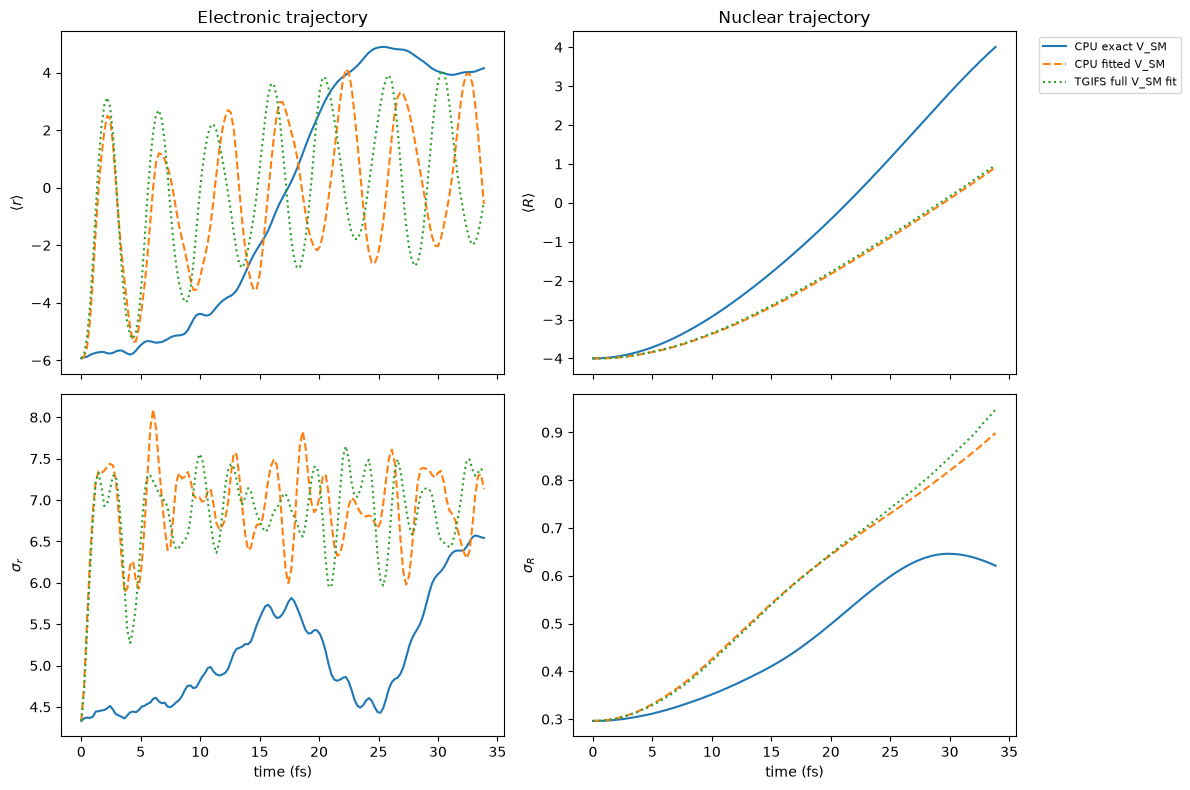

In [56]:
Xr_cpu = X_fock(Nr)
XR_cpu = X_fock(NR)

r_operator_cpu = r0 * np.eye(Nr) + l_r * Xr_cpu
R_operator_cpu = R0 * np.eye(NR) + l_R * XR_cpu
r2_operator_cpu = r_operator_cpu @ r_operator_cpu
R2_operator_cpu = R_operator_cpu @ R_operator_cpu


def cpu_moments(psi_t):
    C = np.asarray(psi_t).reshape(len(psi_t), Nr, NR)

    mean_r = np.einsum('tna,nm,tma->t', C.conj(), r_operator_cpu, C, optimize=True).real
    mean_r2 = np.einsum('tna,nm,tma->t', C.conj(), r2_operator_cpu, C, optimize=True).real

    mean_R = np.einsum('tna,ab,tnb->t', C.conj(), R_operator_cpu, C, optimize=True).real
    mean_R2 = np.einsum('tna,ab,tnb->t', C.conj(), R2_operator_cpu, C, optimize=True).real

    sigma_r = np.sqrt(np.maximum(mean_r2 - mean_r**2, 0.0))
    sigma_R = np.sqrt(np.maximum(mean_R2 - mean_R**2, 0.0))

    return mean_r, sigma_r, mean_R, sigma_R


# Reload from disk for the final comparison.
psi_t_exact_disk = np.load(exact_file, allow_pickle=False)['psi_t']
psi_t_fit_disk = np.load(fit_file, allow_pickle=False)['psi_t']
qres_disk = dict(np.load(qiskit_file, allow_pickle=False))

mr_exact, sr_exact, mR_exact, sR_exact = cpu_moments(psi_t_exact_disk)
mr_fit, sr_fit, mR_fit, sR_fit = cpu_moments(psi_t_fit_disk)

t_fs = times * AU_TIME_TO_FS

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex='col')

axes[0,0].plot(t_fs, mr_exact, label='CPU exact V_SM')
axes[0,0].plot(t_fs, mr_fit, '--', label='CPU fitted V_SM')
axes[0,0].plot(t_fs, qres_disk['mean_r'], ':', label='TGIFS full V_SM fit')
axes[0,0].set_ylabel(r'$\langle r\rangle$')
axes[0,0].set_title('Electronic trajectory')

axes[0,1].plot(t_fs, mR_exact, label='CPU exact V_SM')
axes[0,1].plot(t_fs, mR_fit, '--', label='CPU fitted V_SM')
axes[0,1].plot(t_fs, qres_disk['mean_R'], ':', label='TGIFS full V_SM fit')
axes[0,1].set_ylabel(r'$\langle R\rangle$')
axes[0,1].set_title('Nuclear trajectory')

axes[1,0].plot(t_fs, sr_exact, label='CPU exact V_SM')
axes[1,0].plot(t_fs, sr_fit, '--', label='CPU fitted V_SM')
axes[1,0].plot(t_fs, qres_disk['sigma_r'], ':', label='TGIFS full V_SM fit')
axes[1,0].set_xlabel('time (fs)')
axes[1,0].set_ylabel(r'$\sigma_r$')

axes[1,1].plot(t_fs, sR_exact, label='CPU exact V_SM')
axes[1,1].plot(t_fs, sR_fit, '--', label='CPU fitted V_SM')
axes[1,1].plot(t_fs, qres_disk['sigma_R'], ':', label='TGIFS full V_SM fit')
axes[1,1].set_xlabel('time (fs)')
axes[1,1].set_ylabel(r'$\sigma_R$')

axes[0,1].legend(fontsize=8, bbox_to_anchor=(1.04, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Ancilla and cutoff diagnostics

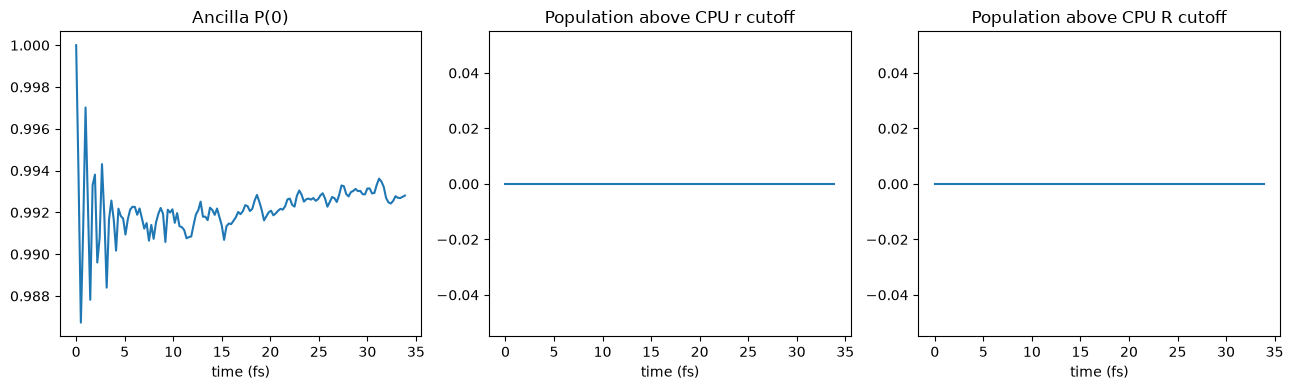

In [57]:
psi_q = np.asarray(qres_disk['psi_t']).reshape(len(times), CUTOFF_r, CUTOFF_R)
prob_q = np.abs(psi_q)**2

leak_r = np.sum(prob_q[:, Nr:, :], axis=(1,2))
leak_R = np.sum(prob_q[:, :, NR:], axis=(1,2))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(t_fs, qres_disk['p0'])
axes[0].set_title('Ancilla P(0)')
axes[0].set_xlabel('time (fs)')

axes[1].plot(t_fs, leak_r)
axes[1].set_title('Population above CPU r cutoff')
axes[1].set_xlabel('time (fs)')

axes[2].plot(t_fs, leak_R)
axes[2].set_title('Population above CPU R cutoff')
axes[2].set_xlabel('time (fs)')

plt.tight_layout()
plt.show()

## Notes on the gate implementation

- `omega` and `Omega` no longer represent harmonic terms in the Hamiltonian. They only choose the Fock-basis coordinate scales `l_r` and `l_R`.
- The full fitted potential is implemented entirely through TGIFS Fourier terms.
- The kinetic energy is a Gaussian free-particle shear, not a phase-space rotation.
- `KINETIC_IMPLEMENTATION='gaussian'` is the hardware-oriented version: rotation + squeezing + rotation.
- `KINETIC_IMPLEMENTATION='matrix'` applies the exact finite-cutoff matrix \(\exp[-i\gamma P^2]\) through `cv_gate_from_matrix`. It is useful to isolate errors in the Gaussian decomposition, but a real device would compile that operator into available Gaussian primitives rather than apply an arbitrary dense matrix natively.
- The constant Fourier coefficient is a global phase and does not affect the plotted observables.
- As in the harmonic-split notebook, TGIFS itself still requires sufficiently small trigonometric-gate angles. The printed `max |theta|` values should therefore be monitored independently of the kinetic implementation.
- The potential fit can now be generated internally with order-weighted ridge + top-N selection + reduced-support refit, or loaded directly from a CSV/TXT file containing the retained modes.
- Result filenames include a sparse-fit tag to avoid accidentally loading a trajectory generated with a different coefficient set.


In [71]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# Settings
# ============================================================

RESULTS_DIR = Path("tgifs_full_potential_results")   # change if needed
#RESULTS_DIR2 = Path("fullV_sparse_fourier_workflow")   # change if needed

# Different retained Fourier-mode counts to compare
TOP_N_LIST = [20, 30, 40]


# ============================================================
# Filename construction
# ============================================================

def make_fit_tag(top_n):
    return (
        f"ridge{RIDGE_LAMBDA:g}"
        f"_ow{ORDER_WEIGHT_STRENGTH:g}"
        f"_op{ORDER_WEIGHT_POWER:g}"
        f"_{TOP_N_SELECTION}_top{top_n}"
        f"_refit{REFIT_RIDGE_MULTIPLIER:g}"
    )


def cpu_fit_filename(top_n):

    box_R, box_r = FOURIER_BOX
    NF_R, NF_r = FOURIER_ORDER

    tag = make_fit_tag(top_n)

    return RESULTS_DIR / (
        f"psi_t_cpu_fit_fullV_{tag}"
        f"_boxR{box_R:g}_boxr{box_r:g}"
        f"_NFR{NF_R}_NFr{NF_r}.npz"
    )


def tgifs_filename(top_n):

    box_R, box_r = FOURIER_BOX
    NF_R, NF_r = FOURIER_ORDER

    tag = make_fit_tag(top_n)

    return RESULTS_DIR / (
        f"psi_t_tgifs_fullV_{KINETIC_IMPLEMENTATION}"
        f"_{tag}"
        f"_boxR{box_R:g}_boxr{box_r:g}"
        f"_NFR{NF_R}_NFr{NF_r}"
        f"_cutr{CUTOFF_r}_cutR{CUTOFF_R}"
        f"_sub{TGIFS_SUBSTEPS}.npz"
    )


exact_cpu_file = (
    RESULTS_DIR
    / "psi_t_cpu_exact_fullV.npz"
)

In [72]:
# ============================================================
# Exact CPU reference
# ============================================================

exact_data = np.load(
    exact_file,
    allow_pickle=False
)

times_exact = exact_data["times"]
psi_t_exact = exact_data["psi_t"]

mr_exact, sr_exact, mR_exact, sR_exact = cpu_moments(
    psi_t_exact
)


# ============================================================
# Load all sparse fitted CPU + TGIFS trajectories
# ============================================================

results = {}


for top_n in TOP_N_LIST:

    cpu_file = cpu_fit_filename(top_n)
    tgifs_file = tgifs_filename(top_n)

    print()
    print(f"N = {top_n}")
    print("CPU:  ", cpu_file)
    print("TGIFS:", tgifs_file)

    if not cpu_file.exists():
        print("  missing fitted CPU")
        continue

    if not tgifs_file.exists():
        print("  missing TGIFS")
        continue


    # --------------------------------------------------------
    # Fitted CPU
    # --------------------------------------------------------

    cpu = np.load(
        cpu_file,
        allow_pickle=False
    )

    psi_t_fit = cpu["psi_t"]

    mr_cpu, sr_cpu, mR_cpu, sR_cpu = cpu_moments(
        psi_t_fit
    )


    # --------------------------------------------------------
    # TGIFS
    # --------------------------------------------------------

    q = np.load(
        tgifs_file,
        allow_pickle=False
    )


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    results[top_n] = {

        "times_cpu": cpu["times"],
        "mean_r_cpu": mr_cpu,
        "sigma_r_cpu": sr_cpu,
        "mean_R_cpu": mR_cpu,
        "sigma_R_cpu": sR_cpu,

        "times_tgifs": q["times"],
        "mean_r_tgifs": q["mean_r"],
        "sigma_r_tgifs": q["sigma_r"],
        "mean_R_tgifs": q["mean_R"],
        "sigma_R_tgifs": q["sigma_R"],

        # useful if you want to inspect it later
        "p0": q["p0"],
    }


N = 20
CPU:   tgifs_full_potential_results/psi_t_cpu_fit_fullV_ridge0.0001_ow10_op1_force_scale_top20_refit1_boxR40_boxr80_NFR14_NFr14.npz
TGIFS: tgifs_full_potential_results/psi_t_tgifs_fullV_gaussian_ridge0.0001_ow10_op1_force_scale_top20_refit1_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub10.npz

N = 30
CPU:   tgifs_full_potential_results/psi_t_cpu_fit_fullV_ridge0.0001_ow10_op1_force_scale_top30_refit1_boxR40_boxr80_NFR14_NFr14.npz
TGIFS: tgifs_full_potential_results/psi_t_tgifs_fullV_gaussian_ridge0.0001_ow10_op1_force_scale_top30_refit1_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub10.npz

N = 40
CPU:   tgifs_full_potential_results/psi_t_cpu_fit_fullV_ridge0.0001_ow10_op1_force_scale_top40_refit1_boxR40_boxr80_NFR14_NFr14.npz
TGIFS: tgifs_full_potential_results/psi_t_tgifs_fullV_gaussian_ridge0.0001_ow10_op1_force_scale_top40_refit1_boxR40_boxr80_NFR14_NFr14_cutr16_cutR128_sub10.npz


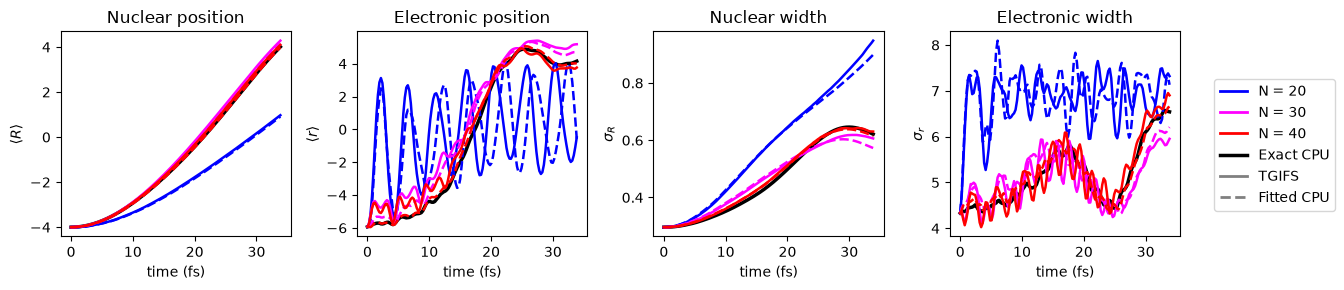

In [84]:
# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(12, 3),
    sharex=True
)

ax_R  = axes[0]#axes[0, 0]
ax_r  = axes[1]#axes[0, 1]
ax_sR = axes[2]#axes[1, 0]
ax_sr = axes[3]#axes[1, 1]


# ------------------------------------------------------------
# Exact CPU reference: black
# ------------------------------------------------------------

t_exact_fs = times_exact * AU_TIME_TO_FS

ax_R.plot(
    t_exact_fs,
    mR_exact,
    color="black",
    lw=2.5
)

ax_r.plot(
    t_exact_fs,
    mr_exact,
    color="black",
    lw=2.5
)

ax_sR.plot(
    t_exact_fs,
    sR_exact,
    color="black",
    lw=2.5
)

ax_sr.plot(
    t_exact_fs,
    sr_exact,
    color="black",
    lw=2.5
)


# ------------------------------------------------------------
# One color per number of Fourier modes
# ------------------------------------------------------------

colors = ("blue","magenta", "red") 
#plt.cm.viridis(
#    np.linspace(
#        0.05,
#        0.95,
#        len(results)
#    )
#)


for color, (top_n, res) in zip(
    colors,
    results.items()
):

    t_cpu = (
        res["times_cpu"]
        * AU_TIME_TO_FS
    )

    t_q = (
        res["times_tgifs"]
        * AU_TIME_TO_FS
    )


    # ========================================================
    # <R>
    # ========================================================

    # TGIFS = solid
    ax_R.plot(
        t_q,
        res["mean_R_tgifs"],
        color=color,
        lw=1.8
    )

    # fitted CPU = dashed
    ax_R.plot(
        t_cpu,
        res["mean_R_cpu"],
        color=color,
        ls="--",
        lw=1.8
    )


    # ========================================================
    # <r>
    # ========================================================

    ax_r.plot(
        t_q,
        res["mean_r_tgifs"],
        color=color,
        lw=1.8
    )

    ax_r.plot(
        t_cpu,
        res["mean_r_cpu"],
        color=color,
        ls="--",
        lw=1.8
    )


    # ========================================================
    # sigma_R
    # ========================================================

    ax_sR.plot(
        t_q,
        res["sigma_R_tgifs"],
        color=color,
        lw=1.8
    )

    ax_sR.plot(
        t_cpu,
        res["sigma_R_cpu"],
        color=color,
        ls="--",
        lw=1.8
    )


    # ========================================================
    # sigma_r
    # ========================================================

    ax_sr.plot(
        t_q,
        res["sigma_r_tgifs"],
        color=color,
        lw=1.8
    )

    ax_sr.plot(
        t_cpu,
        res["sigma_r_cpu"],
        color=color,
        ls="--",
        lw=1.8
    )


# ============================================================
# Labels
# ============================================================

ax_R.set_ylabel(
    r"$\langle R\rangle$"
)

ax_r.set_ylabel(
    r"$\langle r\rangle$"
)

ax_sR.set_ylabel(
    r"$\sigma_R$"
)

ax_sr.set_ylabel(
    r"$\sigma_r$"
)

ax_R.set_xlabel(
    "time (fs)"
)

ax_r.set_xlabel(
    "time (fs)"
)

ax_sR.set_xlabel(
    "time (fs)"
)

ax_sr.set_xlabel(
    "time (fs)"
)

ax_R.set_title(
    "Nuclear position"
)

ax_r.set_title(
    "Electronic position"
)

ax_sR.set_title(
    "Nuclear width"
)

ax_sr.set_title(
    "Electronic width"
)


#for ax in axes.ravel():
#    ax.grid(
#        alpha=0.2
#    )


# ============================================================
# Clean legend
#
# Colors -> number of retained modes
# Line style -> calculation type
# ============================================================

mode_handles = [
    Line2D(
        [0],
        [0],
        color=color,
        lw=2,
        label=f"N = {top_n}"
    )
    for color, top_n in zip(
        colors,
        results.keys()
    )
]

style_handles = [

    Line2D(
        [0],
        [0],
        color="black",
        lw=2.5,
        label="Exact CPU"
    ),

    Line2D(
        [0],
        [0],
        color="gray",
        lw=2,
        ls="-",
        label="TGIFS"
    ),

    Line2D(
        [0],
        [0],
        color="gray",
        lw=2,
        ls="--",
        label="Fitted CPU"
    ),
]


fig.legend(
    handles=mode_handles + style_handles,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5)
)

plt.tight_layout(
    #rect=[0, 0, 0.84, 1]
)

plt.show()